# FEM Laboratory · 02
## Adaptivity, error indicators and heat flow

Experiments for Chapter **1.1**, sections 7–9. This notebook is self-contained.
[Chapter guide](README.md) · [Setup and outputs](NOTEBOOK_README.md) · [Practical exercises](exercises/FEM_Foundations_Exercises.ipynb)

Python 3.11+; CPU / float64; NumPy/SciPy FEM. Run all cells in a fresh kernel.
First decide **where** to put spatial resolution, then decide **how** to step in time.


In [1]:
import platform
import numpy as np
import scipy
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.linalg import eigh
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=4, suppress=True)
SEED = 7
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449"}
plt.rcParams.update({"figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.labelcolor": palette["ink"], "text.color": palette["ink"],
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "axes.titleweight": "bold", "grid.alpha": .35, "lines.linewidth": 2.2,
    "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "navy", "pink", "blue"]])})
print(f"Python {platform.python_version()} · NumPy {np.__version__} · SciPy {scipy.__version__}")
print("CPU / float64 / deterministic quadrature / seed", SEED)


Python 3.13.9 · NumPy 2.4.2 · SciPy 1.17.0
CPU / float64 / deterministic quadrature / seed 7


In [2]:
# Shared mathematical scaffold, repeated here so this notebook runs independently.
def assemble_p1(nodes, forcing=lambda x: np.zeros_like(x), diffusion=lambda x: np.ones_like(x)):
    """P1 stiffness, consistent mass and load; five-point Gauss quadrature."""
    nodes = np.asarray(nodes, dtype=np.float64)
    assert np.all(np.diff(nodes) > 0)
    z, w = np.polynomial.legendre.leggauss(5)
    phi = np.column_stack(((1-z)/2, (1+z)/2))
    rows, cols, stiffness, mass = [], [], [], []
    load = np.zeros(len(nodes))
    for e, h in enumerate(np.diff(nodes)):
        q = nodes[e] + (z+1)*h/2
        ke = np.array([[1., -1.], [-1., 1.]]) * np.dot(w, diffusion(q))/(2*h)
        me = h/6 * np.array([[2., 1.], [1., 2.]])
        fe = h/2 * (phi.T @ (w*forcing(q)))
        for i in range(2):
            load[e+i] += fe[i]
            for j in range(2):
                rows.append(e+i); cols.append(e+j)
                stiffness.append(ke[i,j]); mass.append(me[i,j])
    shape = (len(nodes), len(nodes))
    return (sparse.coo_matrix((stiffness, (rows, cols)), shape=shape).tocsr(),
            sparse.coo_matrix((mass, (rows, cols)), shape=shape).tocsr(), load)

def solve_dirichlet(K, load, values=(0., 0.)):
    uh = np.zeros(K.shape[0]); uh[[0,-1]] = values
    uh[1:-1] = spsolve(K[1:-1, 1:-1], load[1:-1] - (K @ uh)[1:-1])
    return uh

def errors_p1(nodes, uh, exact, derivative):
    z, w = np.polynomial.legendre.leggauss(8)
    h = np.diff(nodes)
    q = nodes[:-1,None] + h[:,None]*(z[None,:]+1)/2
    discrete = uh[:-1,None]*(1-z)/2 + uh[1:,None]*(1+z)/2
    gradient = np.diff(uh)/h
    L2_sq = np.sum(h[:,None]/2*w*(discrete-exact(q))**2)
    H1_sq = np.sum(h[:,None]/2*w*(gradient[:,None]-derivative(q))**2)
    return np.sqrt([L2_sq, H1_sq])


## 1 · A narrow feature hidden inside a smooth solution

Let $u=\exp[-\alpha(x-c)^2]-[(1-x)g(0)+xg(1)]$ with $g(x)=\exp[-\alpha(x-c)^2]$.
It satisfies homogeneous Dirichlet data and has a sharp feature near $c=0.37$.
With P1 elements, the cellwise second derivative of $u_h$ is zero, so an indicator
combines $h_K^2\|f\|_K^2$ with jumps of $u_h'$ across interfaces. This is an error
**indicator**, not a certified upper bound with known reliability constant.


In [3]:
alpha, center = 500., .37
g = lambda x: np.exp(-alpha*(x-center)**2)
g0, g1 = g(0.), g(1.)
exact = lambda x: g(x)-((1-x)*g0+x*g1)
derivative = lambda x: -2*alpha*(x-center)*g(x)+g0-g1
forcing = lambda x: (2*alpha-4*alpha**2*(x-center)**2)*g(x)


In [4]:
def residual_indicators(nodes, uh, forcing):
    """1D residual indicator: cell h²||f||² plus shared derivative jumps."""
    h = np.diff(nodes)
    z, w = np.polynomial.legendre.leggauss(8)
    q = nodes[:-1,None] + h[:,None]*(z+1)/2
    eta2 = h**3/2 * np.sum(w*forcing(q)**2, axis=1)
    jumps = np.diff(np.diff(uh)/h)
    eta2[:-1] += .5*h[:-1]*jumps**2
    eta2[1:] += .5*h[1:]*jumps**2
    return eta2

def mark_and_refine(nodes, eta2, fraction=.5):
    assert 0 < fraction <= 1
    order = np.argsort(eta2)[::-1]
    count = np.searchsorted(np.cumsum(eta2[order]), fraction*eta2.sum())+1
    marked = order[:count]
    midpoints = (nodes[marked]+nodes[marked+1])/2
    return np.sort(np.concatenate((nodes, midpoints)))


## 2 · Solve → estimate → mark → refine

Dörfler marking selects the smallest sorted set whose squared indicators contain
at least half their total. Compare with uniform meshes at approximately the same
number of degrees of freedom; comparing only refinement iteration numbers would be misleading.


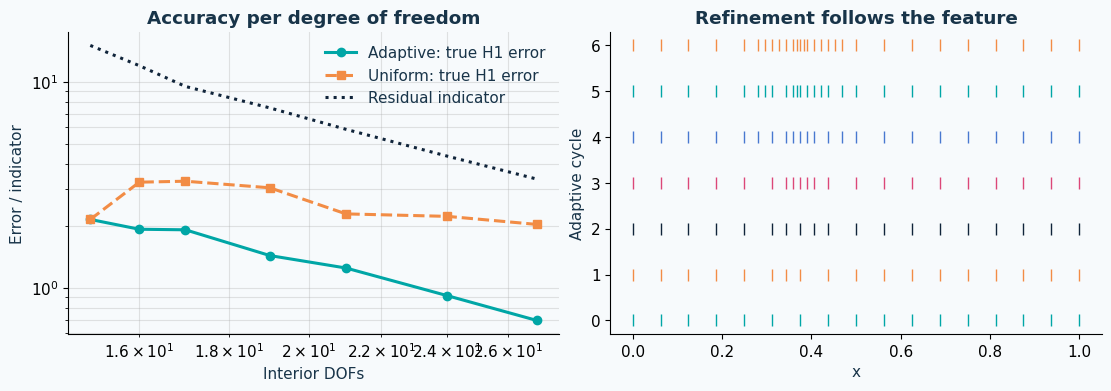

Final indicator / H1 error: 4.863083648601792
Final adaptive / uniform H1 error: 0.34141630132732914


In [5]:
nodes = np.linspace(0,1,17)
adaptive, uniform, meshes = [], [], []
for cycle in range(7):
    K, _, b = assemble_p1(nodes, forcing); uh = solve_dirichlet(K,b)
    eta2 = residual_indicators(nodes,uh,forcing)
    adaptive.append((len(nodes)-2, errors_p1(nodes,uh,exact,derivative)[1], np.sqrt(eta2.sum())))
    meshes.append(nodes.copy())
    xu = np.linspace(0,1,len(nodes)); Ku,_,bu = assemble_p1(xu,forcing)
    uniform.append((len(xu)-2, errors_p1(xu,solve_dirichlet(Ku,bu),exact,derivative)[1]))
    if cycle < 6: nodes = mark_and_refine(nodes,eta2)
adaptive, uniform = np.array(adaptive),np.array(uniform)
assert adaptive[-1,1] < adaptive[0,1]
fig, axs = plt.subplots(1,2,figsize=(11,3.8),layout="constrained")
axs[0].loglog(adaptive[:,0],adaptive[:,1],"o-",label="Adaptive: true H1 error")
axs[0].loglog(uniform[:,0],uniform[:,1],"s--",label="Uniform: true H1 error")
axs[0].loglog(adaptive[:,0],adaptive[:,2],":",label="Residual indicator")
axs[0].set(xlabel="Interior DOFs",ylabel="Error / indicator",title="Accuracy per degree of freedom")
axs[0].legend(); axs[0].grid(which="both")
for j, x in enumerate(meshes): axs[1].plot(x,np.full_like(x,j),"|",ms=9)
axs[1].set(xlabel="x",ylabel="Adaptive cycle",title="Refinement follows the feature")
plt.show()
print("Final indicator / H1 error:", adaptive[-1,2]/adaptive[-1,1])
print("Final adaptive / uniform H1 error:",adaptive[-1,1]/uniform[-1,1])


## 3 · The mass matrix controls the time-step restriction

For $u_t-u_{xx}=0$, $M\dot U+KU=0$. The theta method solves
$(M+\theta\Delta tK)U^{n+1}=(M-(1-\theta)\Delta tK)U^n$.
Forward Euler needs $\Delta t\lambda_{\max}(K,M)\le2$; backward Euler and
Crank–Nicolson are unconditionally stable in the discrete $L^2$ norm.
Unconditional stability does not imply accurate time integration.

A tiny high-frequency perturbation makes explicit instability visible without
relying on machine roundoff. All three methods use the consistent mass matrix.


In [6]:
def theta_heat(n=32, theta=1., dt=.002, final_time=.04, high_frequency=.0):
    x = np.linspace(0, 1, n+1)
    K, M, _ = assemble_p1(x)
    Ki, Mi = K[1:-1,1:-1], M[1:-1,1:-1]
    steps = max(1, int(np.ceil(final_time/dt))); dt = final_time/steps
    u0 = np.sin(np.pi*x[1:-1]) + high_frequency*np.sin((n-1)*np.pi*x[1:-1])
    A = (Mi+theta*dt*Ki).tocsc()
    solve = sparse.linalg.factorized(A)
    B = Mi-(1-theta)*dt*Ki
    u = u0.copy(); energies = [.5*u @ (Mi @ u)]
    for _ in range(steps):
        u = solve(B @ u)
        energies.append(.5*u @ (Mi @ u))
    result = np.zeros(n+1); result[1:-1] = u
    return x, result, np.linspace(0,final_time,steps+1), np.array(energies), dt


Forward Euler: stable     : dt*lambda_max=1.591, E(T)/E(0)=0.789
Forward Euler: unstable   : dt*lambda_max=2.568, E(T)/E(0)=6.4e+11
Crank–Nicolson            : dt*lambda_max=24.399, E(T)/E(0)=0.789
Backward Euler            : dt*lambda_max=24.399, E(T)/E(0)=0.791


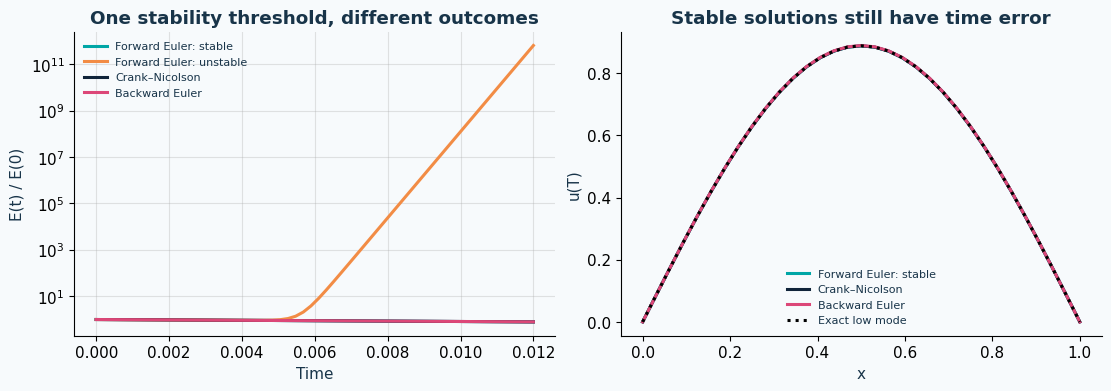

In [7]:
n = 32
x = np.linspace(0,1,n+1); K,M,_=assemble_p1(x)
lambda_max = eigh(K[1:-1,1:-1].toarray(),M[1:-1,1:-1].toarray(),eigvals_only=True)[-1]
dt_limit = 2/lambda_max
cases = [("Forward Euler: stable",0.,.8*dt_limit),
         ("Forward Euler: unstable",0.,1.3*dt_limit),
         ("Crank–Nicolson",.5,.002),("Backward Euler",1.,.002)]
fig,axs=plt.subplots(1,2,figsize=(11,3.8),layout="constrained")
for label,theta,dt in cases:
    x,u,t,E,used_dt=theta_heat(n,theta,dt,final_time=.012,high_frequency=1e-5)
    line, = axs[0].semilogy(t,E/E[0],label=label)
    if "unstable" not in label: axs[1].plot(x,u,label=label,color=line.get_color())
    print(f"{label:26s}: dt*lambda_max={used_dt*lambda_max:.3f}, E(T)/E(0)={E[-1]/E[0]:.3g}")
    if theta >= .5: assert np.max(np.diff(E)) < 1e-12
axs[0].set(xlabel="Time",ylabel="E(t) / E(0)",title="One stability threshold, different outcomes")
axs[0].legend(fontsize=8);axs[0].grid()
axs[1].plot(x,np.exp(-np.pi**2*.012)*np.sin(np.pi*x),"k:",label="Exact low mode")
axs[1].set(xlabel="x",ylabel="u(T)",title="Stable solutions still have time error")
axs[1].legend(fontsize=8);plt.show()


## 4 · Separate time error from spatial error

Use the exact **semidiscrete** solution $U(t)=\exp(-M^{-1}Kt)U(0)$ as the
reference when measuring temporal order. Otherwise the spatial error eventually
hides time convergence. Here a generalized eigenvector gives that reference directly.


In [8]:
values, vectors = eigh(K[1:-1,1:-1].toarray(),M[1:-1,1:-1].toarray())
u0 = vectors[:,0]; final_time=.1
reference = np.exp(-values[0]*final_time)*u0
for theta,label in [(1.,"Backward Euler"),(.5,"Crank–Nicolson")]:
    time_errors=[]
    for steps in [10,20,40,80]:
        dt=final_time/steps
        amplitude=((1-(1-theta)*dt*values[0])/(1+theta*dt*values[0]))**steps
        err=amplitude*u0-reference
        time_errors.append(np.sqrt(err @ (M[1:-1,1:-1] @ err)))
    rates=np.log2(np.array(time_errors[:-1])/time_errors[1:])
    print(label, "errors:",np.array(time_errors),"last rate:",rates[-1])
    assert abs(rates[-1]-(1 if theta==1 else 2)) < .06


Backward Euler errors: [0.0174 0.0089 0.0045 0.0023] last rate: 0.9926037713822137
Crank–Nicolson errors: [0.0003 0.0001 0.     0.    ] last rate: 2.0000718204231758


## Try next

Move the narrow feature and vary the marking fraction. Report true error versus DOFs,
not just indicator reduction. Repeat the heat comparison with a nonsmooth initial state:
Crank–Nicolson damps high frequencies much less than backward Euler. Which diagnostic
separates stability, accuracy, and physical monotonicity?
